# Football Event Recognition: ML Pipeline Notebook

**Author:** Ivan Olivier Muhoza, BSc Software Engineering, ALU
**Course:** Machine Learning Pipeline (MLOP), Summative

This project continues my Intro to ML summative, *"Does Money Buy Wins?"*. That project **predicted** match outcomes from tabular financial and sporting data. This one **recognises what is happening in a match** from a single broadcast image, using 7 event classes:

`Corner_Kick, Free_Kick, Penalty_kick, Red_Card, Yellow_Card, substitute, tackle`

The notebook covers data acquisition, EDA (feature interpretations), preprocessing, model creation (MobileNetV2 transfer learning with optimisation), evaluation with several metrics, testing on an external dataset, and exporting the model for the API.

> **Runtime:** use *Runtime → Change runtime type → T4 GPU* before running.

## 1. Setup and data acquisition

In [ ]:
import os, json, random, time, shutil, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, cohen_kappa_score, log_loss,
                             classification_report, confusion_matrix)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__, "| Keras", tf.keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | Keras 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Both datasets are public on Kaggle; kagglehub downloads them straight into Colab.
import kagglehub
MAIN_PATH = kagglehub.dataset_download("rishintiw/soccer-event-classification-image-data-cnn-and-llm")
EXT_PATH  = kagglehub.dataset_download("noorsaeed/soccer-testset")
print(MAIN_PATH); print(EXT_PATH)

100%|██████████| 1.20G/1.20G [00:16<00:00, 78.1MB/s]

Extracting files...


100%|██████████| 876M/876M [00:10<00:00, 89.0MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/rishintiw/soccer-event-classification-image-data-cnn-and-llm/versions/1
/root/.cache/kagglehub/datasets/noorsaeed/soccer-testset/versions/1


In [ ]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}
def find_class_root(root, marker):
    # Return the directory that directly contains the class folder `marker`.
    for dirpath, dirnames, _ in os.walk(root):
        if marker in dirnames:
            return dirpath
    raise FileNotFoundError(marker)

MAIN_ROOT = find_class_root(MAIN_PATH, "Corner_Kick")
EXT_ROOT  = find_class_root(EXT_PATH, "Corner")
CLASS_NAMES = sorted(d for d in os.listdir(MAIN_ROOT) if os.path.isdir(os.path.join(MAIN_ROOT, d)))
print("Classes:", CLASS_NAMES)

def list_images(root, classes):
    rows = []
    for c in classes:
        folder = os.path.join(root, c)
        for f in os.listdir(folder):
            if os.path.splitext(f)[1].lower() in IMG_EXTS:
                rows.append((os.path.join(folder, f), c))
    return pd.DataFrame(rows, columns=["path", "label"])

df = list_images(MAIN_ROOT, CLASS_NAMES)
print(len(df), "image files")

Classes: ['Corner_Kick', 'Free_Kick', 'Penalty_kick', 'Red_Card', 'Yellow_Card', 'substitute', 'tackle']
6128 image files


## 2. Data cleaning
Drop files that are corrupt or in a format TensorFlow can't decode, and record each image's size and colour statistics for the EDA.

In [ ]:
def image_stats(path):
    try:
        with Image.open(path) as im:
            fmt = im.format
            im = im.convert("RGB")
            w, h = im.size
            a = np.asarray(im.resize((128, 128)), dtype=np.float32)
    except Exception:
        return None
    r, g, b = a[..., 0], a[..., 1], a[..., 2]
    green = (g > r + 10) & (g > b + 10)                 # grass-like pixels
    red   = (r > 150) & (r > g + 60) & (r > b + 60)     # strong red (cards, kits)
    yellow= (r > 150) & (g > 150) & (b < 100)           # strong yellow
    return dict(format=fmt, width=w, height=h, aspect=w / h,
                brightness=a.mean(), green_ratio=green.mean(),
                red_ratio=red.mean(), yellow_ratio=yellow.mean())

t = time.time()
stats = [image_stats(p) for p in df.path]
ok = [s is not None and s["format"] in {"JPEG", "PNG", "BMP"} for s in stats]
print(f"Checked {len(df)} images in {time.time()-t:.0f}s; dropping {len(df)-sum(ok)} unreadable/unsupported")
df = pd.concat([df[ok].reset_index(drop=True),
                pd.DataFrame([s for s, k in zip(stats, ok) if k])], axis=1)
df.head()

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Checked 6128 images in 130s; dropping 150 unreadable/unsupported


,path,label,format,width,height,aspect,brightness,green_ratio,red_ratio,yellow_ratio
0,/root/.cache/kagglehub/datasets/rishintiw/socc...,Corner_Kick,JPEG,270,186,1.451613,93.788513,0.209229,0.073608,0.000671
1,/root/.cache/kagglehub/datasets/rishintiw/socc...,Corner_Kick,JPEG,544,358,1.519553,80.028419,0.826843,0.006836,0.003479
2,/root/.cache/kagglehub/datasets/rishintiw/socc...,Corner_Kick,JPEG,600,900,0.666667,138.183350,0.478943,0.012573,0.016968
3,/root/.cache/kagglehub/datasets/rishintiw/socc...,Corner_Kick,JPEG,200,122,1.639344,160.269836,0.034668,0.057068,0.002075
4,/root/.cache/kagglehub/datasets/rishintiw/socc...,Corner_Kick,JPEG,1280,720,1.777778,88.848694,0.414734,0.036072,0.042175


## 3. Exploratory data analysis and feature interpretation

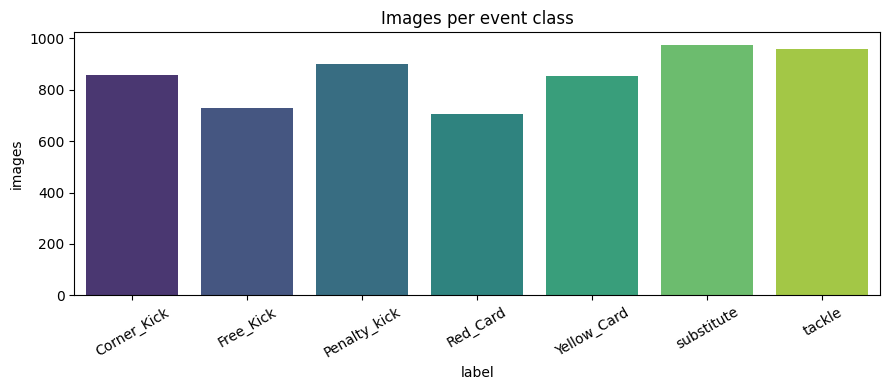

label
Corner_Kick     856
Free_Kick       729
Penalty_kick    901
Red_Card        707
Yellow_Card     852
substitute      974
tackle          959
Name: count, dtype: int64
Imbalance ratio (max/min): 1.38


In [ ]:
os.makedirs("figures", exist_ok=True)
counts = df.label.value_counts().reindex(CLASS_NAMES)
plt.figure(figsize=(9, 4))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette="viridis", legend=False)
plt.title("Images per event class"); plt.ylabel("images"); plt.xticks(rotation=30)
plt.tight_layout(); plt.savefig("figures/class_distribution.png", dpi=120); plt.show()
print(counts); print("Imbalance ratio (max/min):", round(counts.max() / counts.min(), 2))

**Feature 1: class balance.** The classes are fairly balanced; the largest is about 1.4× the smallest. Red cards and free kicks are the rarest. That mirrors real matches, where a red card is rarer than a tackle. Class weights are still used during training so the rarer events aren't under-predicted. In my Intro to ML project, the model never predicted the minority class (draws).

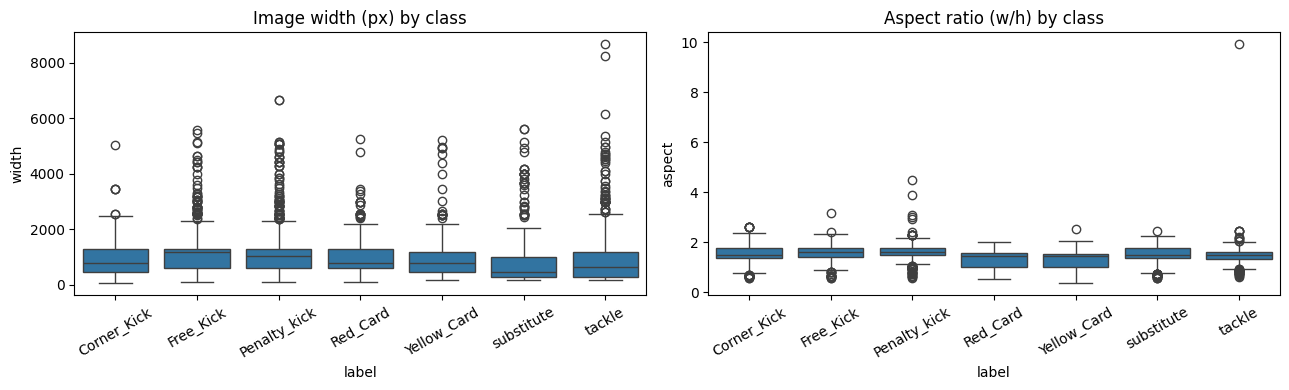

,width,height,aspect
label,,,
Corner_Kick,800.0,568.5,1.502732
Free_Kick,1200.0,720.0,1.599109
Penalty_kick,1024.0,640.0,1.626016
Red_Card,800.0,700.0,1.436266
Yellow_Card,800.0,600.0,1.429830
substitute,465.0,306.0,1.502732
tackle,640.0,435.0,1.499707


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="label", y="width", order=CLASS_NAMES, ax=ax[0]); ax[0].set_title("Image width (px) by class")
sns.boxplot(data=df, x="label", y="aspect", order=CLASS_NAMES, ax=ax[1]); ax[1].set_title("Aspect ratio (w/h) by class")
for a in ax: a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("figures/image_size.png", dpi=120); plt.show()
df.groupby("label")[["width", "height", "aspect"]].median()

**Feature 2: resolution and aspect ratio.** Image sizes vary a lot between and within classes. Median widths range from about 465 px (substitutions, often small screenshots) to 1,200 px (free kicks), and most frames are wide landscape shots with a median aspect ratio of about 1.4–1.6 (roughly 3:2). Because the model can't rely on a fixed input size, every image is **resized to 224×224** during preprocessing. That's also MobileNetV2's native input size. Some distortion of wide frames is accepted in exchange for a consistent input.

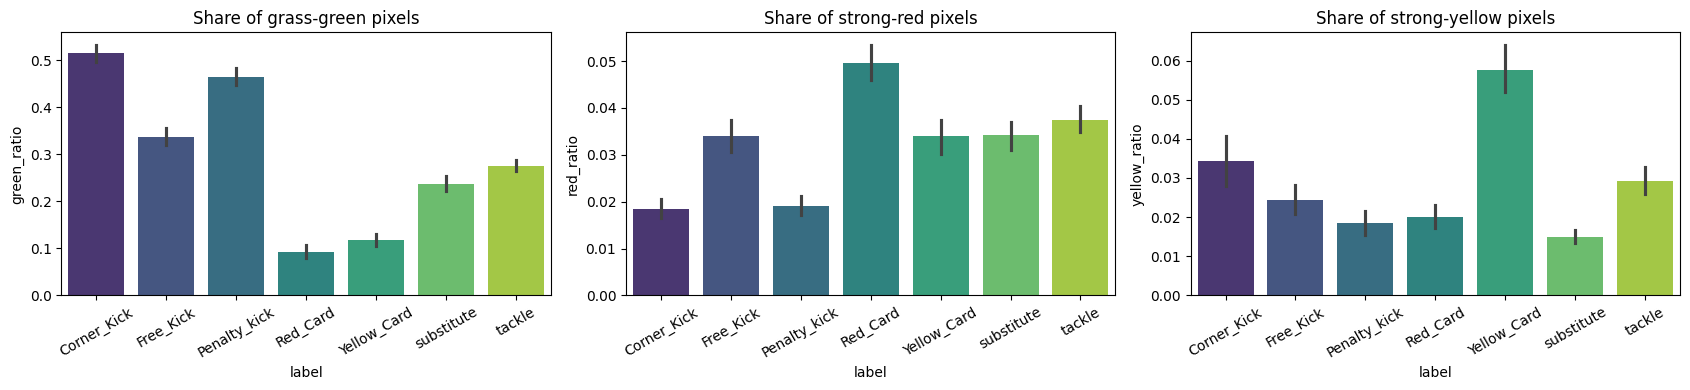

,brightness,green_ratio,red_ratio,yellow_ratio
label,,,,
Corner_Kick,100.693001,0.515,0.018,0.034
Free_Kick,97.023003,0.337,0.034,0.024
Penalty_kick,99.115997,0.465,0.019,0.018
Red_Card,122.206001,0.093,0.049,0.020
Yellow_Card,112.174004,0.117,0.034,0.058
substitute,90.517998,0.238,0.034,0.015
tackle,98.768997,0.275,0.038,0.029


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for a, col, title in zip(ax, ["green_ratio", "red_ratio", "yellow_ratio"],
                         ["Share of grass-green pixels", "Share of strong-red pixels", "Share of strong-yellow pixels"]):
    sns.barplot(data=df, x="label", y=col, order=CLASS_NAMES, ax=a, hue="label", hue_order=CLASS_NAMES, palette="viridis", legend=False, errorbar=("ci", 95))
    a.set_title(title); a.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("figures/colour_features.png", dpi=120); plt.show()
df.groupby("label")[["brightness", "green_ratio", "red_ratio", "yellow_ratio"]].mean().round(3)

**Feature 3: colour composition (what the camera shows).**
- **Grass-green share** separates *wide set-piece shots* from *close-ups*. Corners (52% green pixels) and penalties (47%) show a lot of pitch. Red-card (9%) and yellow-card (12%) images focus on a referee or player.
- **Red and yellow pixel shares** are the visual signature of the two card classes. Red-card images have the highest red share (5.0%) and yellow-card images the highest yellow share (5.8%). The differences are small because kits and advertising boards contain the same colours. Colour alone can't separate the classes, so a CNN that learns shapes and context (a raised arm holding a card) is needed. The confusion matrix confirms that most remaining errors are between visually similar set pieces (free kick ↔ penalty ↔ corner) and between the two card colours.

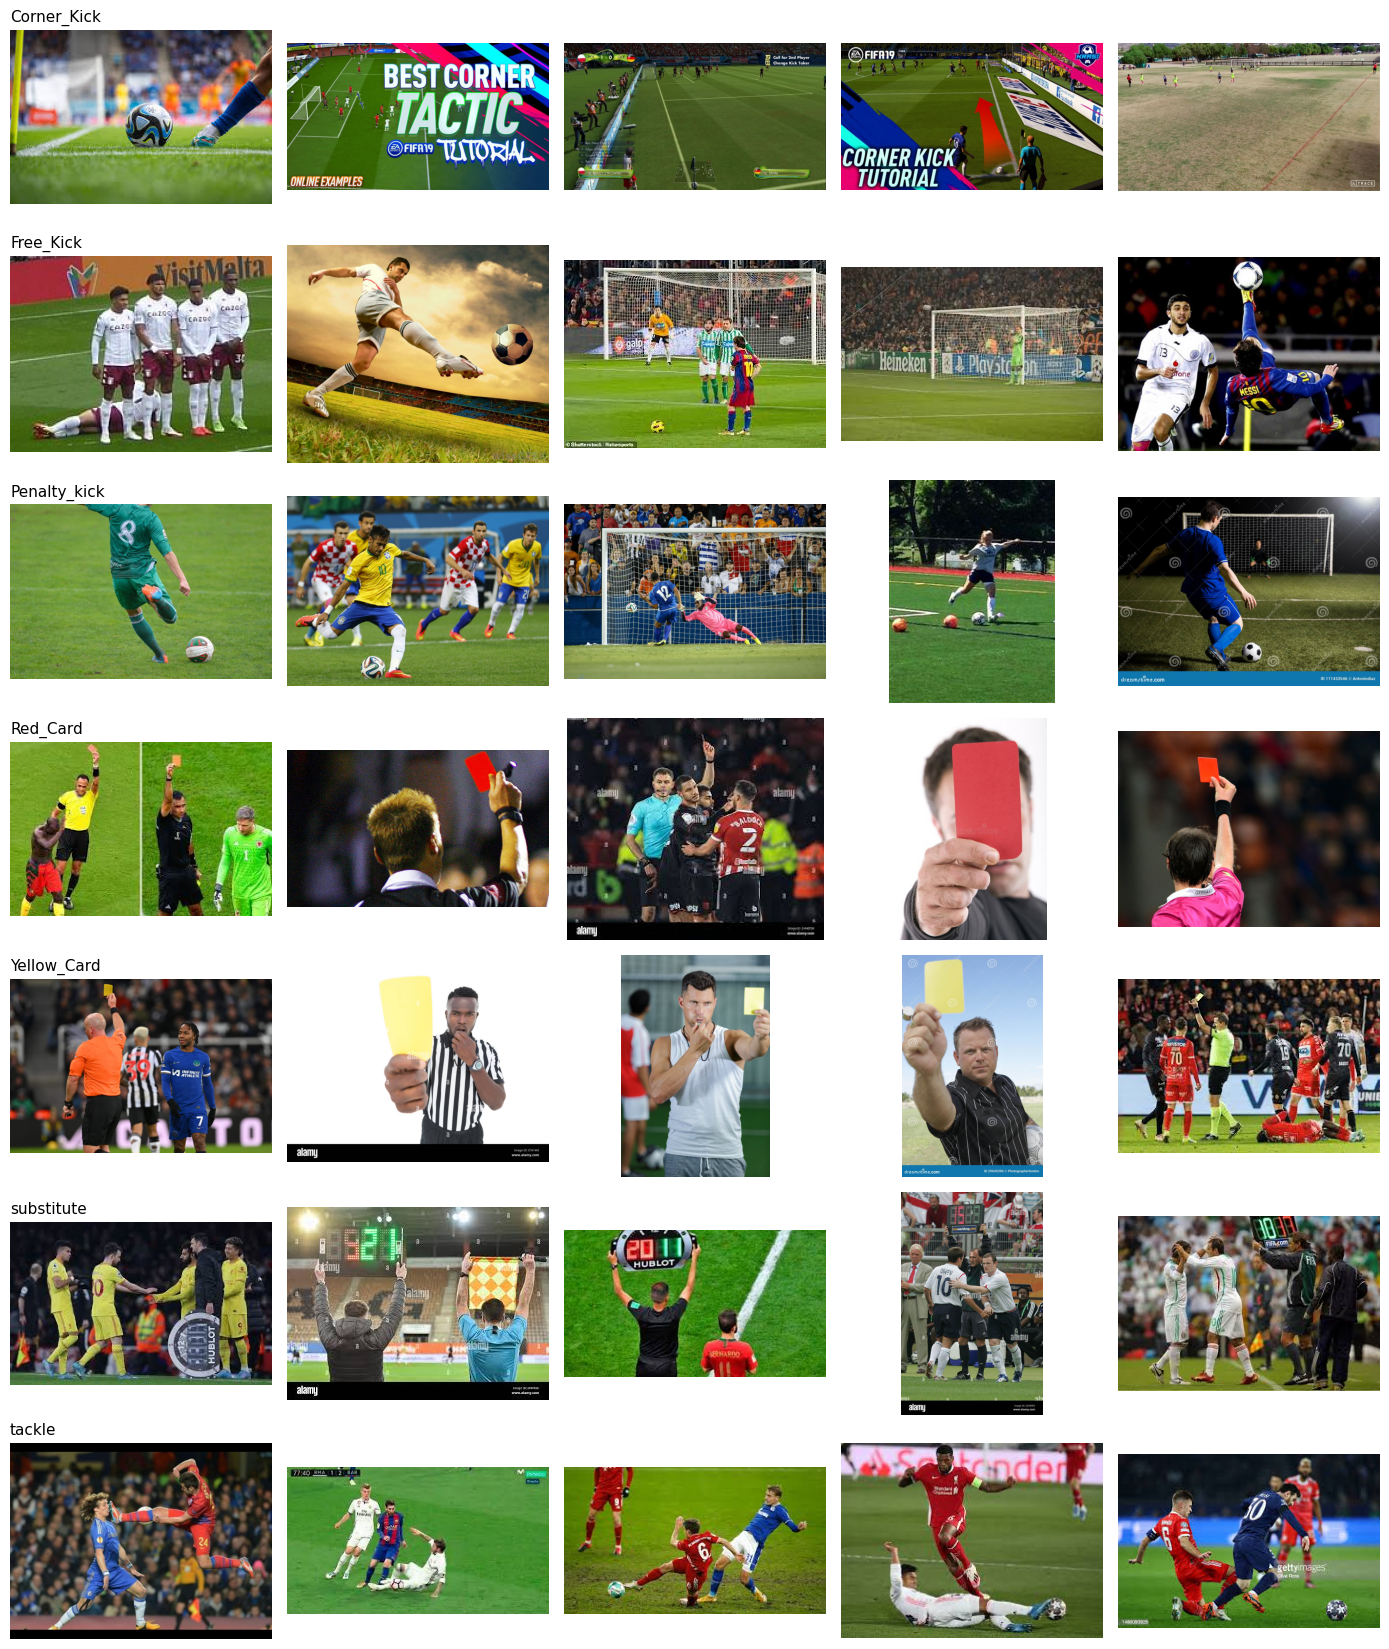

In [ ]:
fig, axes = plt.subplots(len(CLASS_NAMES), 5, figsize=(14, 2.4 * len(CLASS_NAMES)))
for i, c in enumerate(CLASS_NAMES):
    for j, p in enumerate(df[df.label == c].sample(5, random_state=SEED).path):
        axes[i, j].imshow(Image.open(p).convert("RGB")); axes[i, j].axis("off")
    axes[i, 0].set_title(c, loc="left", fontsize=11)
plt.tight_layout(); plt.savefig("figures/samples.png", dpi=90); plt.show()

## 4. Preprocessing
- A stratified **70 / 15 / 15** train / validation / test split.
- A `tf.data` pipeline: decode → resize to 224×224 → batch → prefetch.
- **Inside the model:** data augmentation (flip, rotation, zoom, contrast), which is active only during training, and rescaling to [-1, 1] for MobileNetV2. Putting these layers in the model means the API sends raw pixels, so training and serving always preprocess the same way.

In [ ]:
IMG_SIZE, BATCH = 224, 32
train_df, tmp = train_test_split(df[["path", "label"]], test_size=0.30, stratify=df.label, random_state=SEED)
val_df, test_df = train_test_split(tmp, test_size=0.50, stratify=tmp.label, random_state=SEED)
print(len(train_df), len(val_df), len(test_df))
cls_idx = {c: i for i, c in enumerate(CLASS_NAMES)}

def load_image(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return tf.cast(img, tf.float32), label

def make_ds(frame, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((frame.path.values, frame.label.map(cls_idx).values))
    if shuffle: ds = ds.shuffle(len(frame), seed=SEED)
    return ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, True), make_ds(val_df), make_ds(test_df)

cw = len(train_df) / (len(CLASS_NAMES) * train_df.label.value_counts())
class_weight = {cls_idx[c]: float(w) for c, w in cw.items()}
class_weight

4184 897 897


{5: 0.8764139086719732,
 6: 0.8907813497977433,
 2: 0.9472492642064749,
 0: 0.9978535654662533,
 4: 1.00287631831256,
 1: 1.1719887955182073,
 3: 1.2075036075036074}

## 5. Model creation: MobileNetV2 transfer learning
**Optimisation techniques used:**
1. A **pretrained model** (MobileNetV2 trained on ImageNet), used as a frozen feature extractor in phase 1.
2. **Regularisation:** dropout (0.3) and L2 (1e-4) on the classifier head, plus data augmentation.
3. The **Adam optimiser** with **ReduceLROnPlateau**.
4. **Early stopping** on validation loss, restoring the best weights.
5. **Fine-tuning** (phase 2): unfreeze the top 40 layers and train at a 100× lower learning rate.

In [ ]:
def build_model(num_classes):
    augment = tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(0.05),
        tf.keras.layers.RandomZoom(0.1),
        tf.keras.layers.RandomContrast(0.1),
    ], name="augmentation")
    base = tf.keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
    base.trainable = False
    inputs = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
    x = augment(inputs)
    x = tf.keras.layers.Rescaling(1 / 127.5, offset=-1, name="mobilenet_preprocess")(x)
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.3)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax",
                                    kernel_regularizer=tf.keras.regularizers.l2(1e-4), name="event")(x)
    return tf.keras.Model(inputs, outputs, name="football_event_mobilenetv2"), base

model, base = build_model(len(CLASS_NAMES))
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "football_event_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocess            │ (None, 224, 224, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ event (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,266,951 (8.65 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
def callbacks(tag):
    return [tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
            tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-7),
            tf.keras.callbacks.CSVLogger(f"history_{tag}.csv")]

h1 = model.fit(train_ds, validation_data=val_ds, epochs=15, class_weight=class_weight, callbacks=callbacks("phase1"))

Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 55s 322ms/step - accuracy: 0.5344 - loss: 1.2978 - val_accuracy: 0.6823 - val_loss: 0.9041 - learning_rate: 0.0010
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 39s 298ms/step - accuracy: 0.7132 - loss: 0.8237 - val_accuracy: 0.7336 - val_loss: 0.7789 - learning_rate: 0.0010
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 39s 295ms/step - accuracy: 0.7574 - loss: 0.7284 - val_accuracy: 0.7536 - val_loss: 0.7245 - learning_rate: 0.0010
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 40s 291ms/step - accuracy: 0.7758 - loss: 0.6601 - val_accuracy: 0.7648 - val_loss: 0.6974 - learning_rate: 0.0010
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 37s 281ms/step - accuracy: 0.7925 - loss: 0.6150 - val_accuracy: 0.7592 - val_loss: 0.7165 - learning_rate: 0.0010
Epoch 6/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 43s 296ms/step - accuracy: 0.7959 - loss: 0.6029 - val_accuracy: 0.7882 - val_loss: 0.6577 - learning_rate: 0.0010
Epoch 7/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 40s 309ms/step - accuracy: 0.8

In [ ]:
# Phase 2: fine-tune the top of the backbone
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False
for layer in base.layers:                 # keep BatchNorm statistics frozen
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=10, class_weight=class_weight, callbacks=callbacks("phase2"))

Epoch 1/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 45s 295ms/step - accuracy: 0.8461 - loss: 0.4817 - val_accuracy: 0.8205 - val_loss: 0.5719 - learning_rate: 1.0000e-05
Epoch 2/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 40s 292ms/step - accuracy: 0.8528 - loss: 0.4279 - val_accuracy: 0.8216 - val_loss: 0.5614 - learning_rate: 1.0000e-05
Epoch 3/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 38s 286ms/step - accuracy: 0.8645 - loss: 0.4081 - val_accuracy: 0.8283 - val_loss: 0.5362 - learning_rate: 1.0000e-05
Epoch 4/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 44s 308ms/step - accuracy: 0.8762 - loss: 0.3705 - val_accuracy: 0.8361 - val_loss: 0.5151 - learning_rate: 1.0000e-05
Epoch 5/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 37s 282ms/step - accuracy: 0.8843 - loss: 0.3466 - val_accuracy: 0.8261 - val_loss: 0.5211 - learning_rate: 1.0000e-05
Epoch 6/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 40s 307ms/step - accuracy: 0.8903 - loss: 0.3329 - val_accuracy: 0.8384 - val_loss: 0.5078 - learning_rate: 1.0000e-05
Epoch 7/10
131/131 ━━━━━━━━━━━━━━━━━━━━ 41s 30

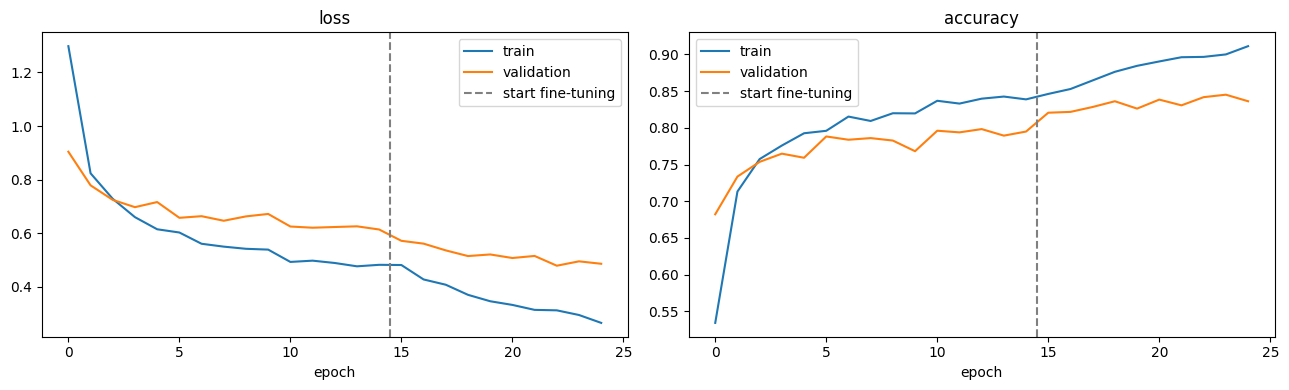

In [ ]:
hist = pd.concat([pd.DataFrame(h1.history), pd.DataFrame(h2.history)], ignore_index=True)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, m in zip(ax, ["loss", "accuracy"]):
    a.plot(hist[m], label="train"); a.plot(hist["val_" + m], label="validation")
    a.axvline(len(h1.history["loss"]) - 0.5, ls="--", c="grey", label="start fine-tuning")
    a.set_title(m); a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig("figures/learning_curves.png", dpi=120); plt.show()

## 6. Evaluation on the held-out test set

== test set
accuracy             0.8673
loss (log loss)      0.4107
precision_macro      0.8637
recall_macro         0.8624
f1_macro             0.8624
f1_weighted          0.8681
roc_auc_ovr_macro    0.9794
cohen_kappa          0.8449
              precision    recall  f1-score   support

 Corner_Kick       0.89      0.82      0.85       129
   Free_Kick       0.67      0.75      0.71       109
Penalty_kick       0.80      0.77      0.78       135
    Red_Card       0.89      0.88      0.88       106
 Yellow_Card       0.90      0.89      0.90       128
  substitute       0.96      0.96      0.96       146
      tackle       0.94      0.97      0.95       144

    accuracy                           0.87       897
   macro avg       0.86      0.86      0.86       897
weighted avg       0.87      0.87      0.87       897



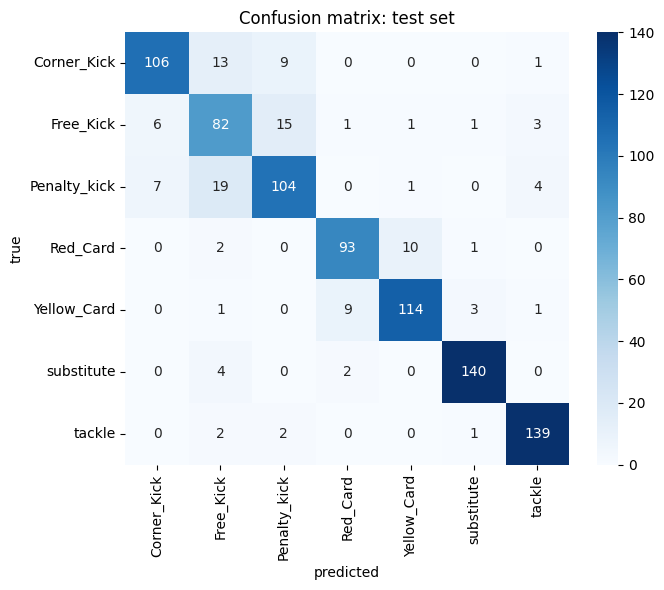

In [ ]:
def evaluate(ds, y_true, name):
    proba = model.predict(ds, verbose=0)
    y_pred = proba.argmax(1)
    labels = list(range(len(CLASS_NAMES)))
    m = {
        "accuracy": accuracy_score(y_true, y_pred),
        "loss (log loss)": log_loss(y_true, proba, labels=labels),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "roc_auc_ovr_macro": roc_auc_score(y_true, proba, multi_class="ovr", labels=labels),
        "cohen_kappa": cohen_kappa_score(y_true, y_pred),
    }
    print(f"== {name}")
    for k, v in m.items(): print(f"{k:20s} {v:.4f}")
    print(classification_report(y_true, y_pred, labels=labels, target_names=CLASS_NAMES, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(f"Confusion matrix: {name}"); plt.ylabel("true"); plt.xlabel("predicted")
    plt.tight_layout(); plt.savefig(f"figures/cm_{name.replace(' ', '_')}.png", dpi=120); plt.show()
    return {k: round(float(v), 4) for k, v in m.items()}

y_test = test_df.label.map(cls_idx).values
test_metrics = evaluate(test_ds, y_test, "test set")

## 7. External test: a different data source
The *Soccer Events TestSet* (`noorsaeed/soccer-testset`) was collected separately. Seven of its classes match ours. Testing on it shows how well the model generalises to a different source (domain shift). The same images are later used in the deployed app as **new data for retraining**.

3500 external images
label
Corner_Kick     500
Free_Kick       500
Penalty_kick    500
Red_Card        500
Yellow_Card     500
tackle          500
substitute      500
Name: count, dtype: int64
== external set
accuracy             0.6157
loss (log loss)      1.3305
precision_macro      0.6848
recall_macro         0.6157
f1_macro             0.6154
f1_weighted          0.6154
roc_auc_ovr_macro    0.9210
cohen_kappa          0.5517
              precision    recall  f1-score   support

 Corner_Kick       0.75      0.71      0.73       500
   Free_Kick       0.38      0.78      0.51       500
Penalty_kick       0.63      0.76      0.69       500
    Red_Card       0.74      0.38      0.50       500
 Yellow_Card       0.68      0.58      0.62       500
  substitute       0.72      0.73      0.73       500
      tackle       0.89      0.37      0.52       500

    accuracy                           0.62      3500
   macro avg       0.68      0.62      0.62      3500
weighted avg       0.68  

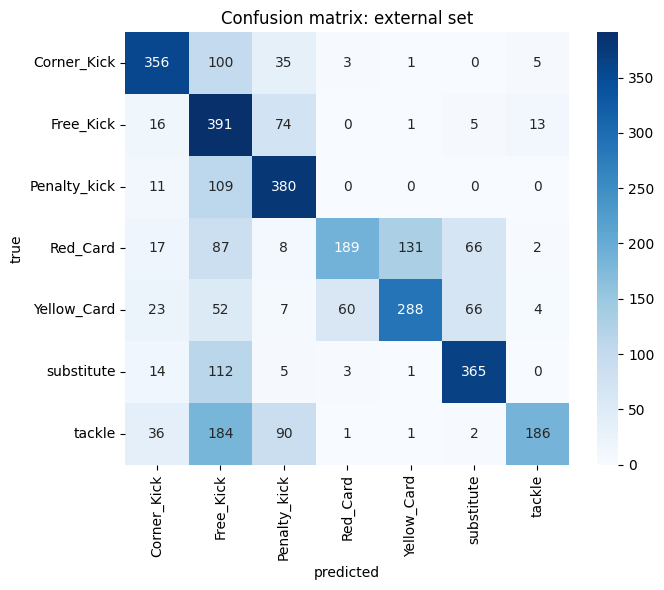

In [ ]:
EXT_MAP = {"Corner": "Corner_Kick", "Free-Kick": "Free_Kick", "Penalty": "Penalty_kick",
           "Red-Cards": "Red_Card", "Yellow-Cards": "Yellow_Card", "Tackle": "tackle", "To-Subtitue": "substitute"}
ext = list_images(EXT_ROOT, list(EXT_MAP))
ext["label"] = ext.label.map(EXT_MAP)
def readable(p):
    s = image_stats(p)
    return s is not None and s["format"] in {"JPEG", "PNG", "BMP"}
ext = ext[[readable(p) for p in ext.path]].reset_index(drop=True)
print(len(ext), "external images"); print(ext.label.value_counts())
ext_metrics = evaluate(make_ds(ext), ext.label.map(cls_idx).values, "external set")

*Interpretation:* compare the external accuracy with the test accuracy. A drop means the new source looks different (camera angles, leagues, image quality). That's exactly the situation the **retraining pipeline** is for: upload images from the new source and fine-tune the saved model on them.

## 8. Prediction function (single image)

In [ ]:
def predict_image(path, top_k=3):
    img, _ = load_image(path, 0)
    proba = model.predict(img[None, ...], verbose=0)[0]
    order = proba.argsort()[::-1][:top_k]
    return [(CLASS_NAMES[i], float(proba[i])) for i in order]

for _, row in test_df.sample(5, random_state=1).iterrows():
    print(f"true={row.label:13s} predicted={predict_image(row.path)}")

true=Penalty_kick  predicted=[('Penalty_kick', 0.9805300235748291), ('Corner_Kick', 0.010142708197236061), ('Free_Kick', 0.00852592010051012)]
true=Yellow_Card   predicted=[('Yellow_Card', 0.9979079961776733), ('Red_Card', 0.002090184250846505), ('Free_Kick', 1.7944072396858246e-06)]
true=tackle        predicted=[('tackle', 0.6892048716545105), ('Free_Kick', 0.1455237865447998), ('Penalty_kick', 0.11376815289258957)]
true=substitute    predicted=[('substitute', 0.9833985567092896), ('Yellow_Card', 0.00982515886425972), ('Penalty_kick', 0.0030247275717556477)]
true=Free_Kick     predicted=[('Free_Kick', 0.7644225358963013), ('Penalty_kick', 0.23296111822128296), ('Red_Card', 0.0013521623332053423)]


## 9. Export model and metadata for deployment
After this cell runs, download `football_event_artifacts.zip` and unzip it into the repo's `models/` folder.

In [ ]:
os.makedirs("export", exist_ok=True)
model.save("export/football_event_model.h5")          # HDF5 file (rubric: .h5)
model.save("export/football_event_model.keras")       # native Keras format
meta = {
    "class_names": CLASS_NAMES, "img_size": IMG_SIZE,
    "tensorflow_version": tf.__version__, "keras_version": tf.keras.__version__,
    "trained_at": time.strftime("%Y-%m-%d %H:%M:%S"),
    "n_train": len(train_df), "n_val": len(val_df), "n_test": len(test_df),
    "test_metrics": test_metrics, "external_metrics": ext_metrics,
    "class_counts": counts.to_dict(),
}
json.dump(meta, open("export/model_meta.json", "w"), indent=2)

eda = df.groupby("label").agg(images=("path", "size"), median_width=("width", "median"),
                              median_height=("height", "median"), median_aspect=("aspect", "median"),
                              brightness=("brightness", "mean"), green_ratio=("green_ratio", "mean"),
                              red_ratio=("red_ratio", "mean"), yellow_ratio=("yellow_ratio", "mean")).round(4)
eda.reset_index().to_json("export/eda_stats.json", orient="records", indent=2)
hist.to_csv("export/training_history.csv", index=False)
shutil.copytree("figures", "export/figures", dirs_exist_ok=True)
shutil.make_archive("football_event_artifacts", "zip", "export")
print(json.dumps(meta, indent=2))

from google.colab import files
files.download("football_event_artifacts.zip")

{
  "class_names": [
    "Corner_Kick",
    "Free_Kick",
    "Penalty_kick",
    "Red_Card",
    "Yellow_Card",
    "substitute",
    "tackle"
  ],
  "img_size": 224,
  "tensorflow_version": "2.21.0",
  "keras_version": "3.13.2",
  "trained_at": "2026-11-24 17:01:00",
  "n_train": 4184,
  "n_val": 897,
  "n_test": 897,
  "test_metrics": {
    "accuracy": 0.8673,
    "loss (log loss)": 0.4107,
    "precision_macro": 0.8637,
    "recall_macro": 0.8624,
    "f1_macro": 0.8624,
    "f1_weighted": 0.8681,
    "roc_auc_ovr_macro": 0.9794,
    "cohen_kappa": 0.8449
  },
  "external_metrics": {
    "accuracy": 0.6157,
    "loss (log loss)": 1.3305,
    "precision_macro": 0.6848,
    "recall_macro": 0.6157,
    "f1_macro": 0.6154,
    "f1_weighted": 0.6154,
    "roc_auc_ovr_macro": 0.921,
    "cohen_kappa": 0.5517
  },
  "class_counts": {
    "Corner_Kick": 856,
    "Free_Kick": 729,
    "Penalty_kick": 901,
    "Red_Card": 707,
    "Yellow_Card": 852,
    "substitute": 974,
    "tackle": 959
 

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>